In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

I0000 00:00:1791871627.756164   28013 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791871631.997279   28013 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Layer, Dense, Add, Embedding  # <<<<============ Add Embegging here
from tensorflow.keras.layers import Activation, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.util import ngrams
import matplotlib.pyplot as plt


In [3]:
sentences = [ 
    "the cat is walking in the bedroom",
    "a dog was running in a room",
    "the cat is running in a room",
    "a dog is walking in a bedroom",
    "the dog was walking in the room"
]

In [4]:
# Data preprocessing
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
word2idx = tokenizer.word_index
idx2word = { v:k for (k,v) in word2idx.items()}
sequences = tokenizer.texts_to_sequences(sentences)

In [5]:
print(word2idx)
print(idx2word)
print(sequences)

{'the': 1, 'in': 2, 'a': 3, 'is': 4, 'walking': 5, 'dog': 6, 'room': 7, 'cat': 8, 'bedroom': 9, 'was': 10, 'running': 11}
{1: 'the', 2: 'in', 3: 'a', 4: 'is', 5: 'walking', 6: 'dog', 7: 'room', 8: 'cat', 9: 'bedroom', 10: 'was', 11: 'running'}
[[1, 8, 4, 5, 2, 1, 9], [3, 6, 10, 11, 2, 3, 7], [1, 8, 4, 11, 2, 3, 7], [3, 6, 4, 5, 2, 3, 9], [1, 6, 10, 5, 2, 1, 7]]


In [6]:
n=4 #4 n-grams
list_ngrams = [list(ngrams(s, n)) for s in sequences]
array_ngrams = np.array(list_ngrams).reshape(-1,n)

print(list_ngrams)
print(array_ngrams)

[[(1, 8, 4, 5), (8, 4, 5, 2), (4, 5, 2, 1), (5, 2, 1, 9)], [(3, 6, 10, 11), (6, 10, 11, 2), (10, 11, 2, 3), (11, 2, 3, 7)], [(1, 8, 4, 11), (8, 4, 11, 2), (4, 11, 2, 3), (11, 2, 3, 7)], [(3, 6, 4, 5), (6, 4, 5, 2), (4, 5, 2, 3), (5, 2, 3, 9)], [(1, 6, 10, 5), (6, 10, 5, 2), (10, 5, 2, 1), (5, 2, 1, 7)]]
[[ 1  8  4  5]
 [ 8  4  5  2]
 [ 4  5  2  1]
 [ 5  2  1  9]
 [ 3  6 10 11]
 [ 6 10 11  2]
 [10 11  2  3]
 [11  2  3  7]
 [ 1  8  4 11]
 [ 8  4 11  2]
 [ 4 11  2  3]
 [11  2  3  7]
 [ 3  6  4  5]
 [ 6  4  5  2]
 [ 4  5  2  3]
 [ 5  2  3  9]
 [ 1  6 10  5]
 [ 6 10  5  2]
 [10  5  2  1]
 [ 5  2  1  7]]


In [7]:
# training data
x_train = array_ngrams[:, :-1]
y_train = array_ngrams[:, -1]

In [8]:
m = 8                   # word embedding size vector
V = len(word2idx) + 1   # vocabulary size
h = 64                  # no. of hidden units

In [9]:
# word embedding layer
class WordEmbedding(Layer):
    def __init__(self, input_dim, emb_size, name=None):
        super(WordEmbedding, self).__init__(name=name)

        # Matrix C registered as a Keras layer weight
        self.C = self.add_weight(
            name='C',
            shape=(input_dim, emb_size),
            initializer='random_normal',
            trainable=True
        )

    def call(self, x):
        # Table look up in C
        selected_rows = tf.gather(self.C, x) # (None, 3, 8)
        return selected_rows
        

In [10]:
# create NPLM model
x_input = Input(batch_shape = (None, x_train.shape[1]), dtype='int32')
# x_embed = WordEmbedding(V, m, name='emb')(x_input)         <<<<<<<<==========chnage this to below
x_embed = Embedding(input_dim=V, output_dim=m, name='emb')(x_input)          #(None,3,8)
x_concat = Flatten()(x_embed)
Hx = Dense(h, activation='tanh')(x_concat)
Wx = Dense(V, use_bias = False)(x_concat)
Ux = Dense(V)(Hx)
y = Add()([Wx, Ux])
y_prob = Activation('softmax')(y)

E0000 00:00:1791871645.828721   28013 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [11]:
model = Model(x_input, y_prob)
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.01)
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb (Embedding)     │ (None, 3, 8)      │         96 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 24)        │          0 │ emb[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      1,600 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 12)        │        288 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 12)        │        780 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 12)        │          0 │ dense_1[0][0],    │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 12)        │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,764 (10.80 KB)

 Trainable params: 2,764 (10.80 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# fit data to the model
hist = model.fit(x_train, y_train, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 727ms/step - loss: 2.4850
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 2.3834
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 2.2729
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 2.1377
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 1.9716
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.7751
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 1.5550
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 1.3244
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 1.1012
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.9045
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.7471
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.6308
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.5485
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 0.4895
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 0.4461
Epoch 16/100
1/1

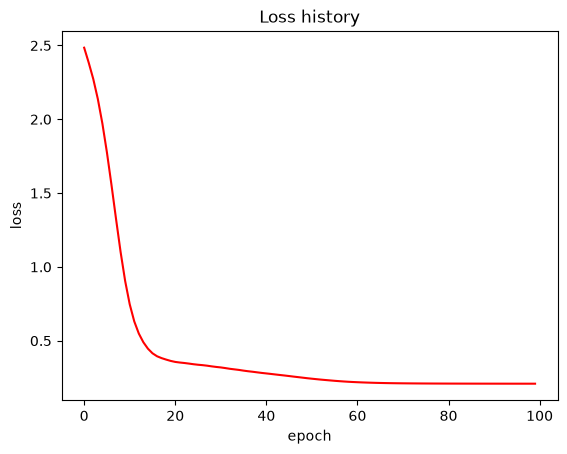

In [13]:
# losss history
plt.plot(hist.history['loss'], color='red')
plt.title("Loss history")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [14]:
# matrix C
C = model.get_layer('emb').get_weights()[0]

In [15]:
# word vector
print("\nWord vectors:")
for word, idx in word2idx.items():
    word_vector = C[idx, :]
    print("{:10s}".format(word), end='')
    print(word_vector.round(3))


Word vectors:
the       [ 0.22   0.43   0.442 -0.413 -0.043  0.042 -0.38   0.422]
in        [-0.583  0.526 -0.234  0.503 -0.274  0.044  0.656 -0.365]
a         [-0.084  0.342 -0.028 -0.382 -0.5    0.3   -0.036  0.315]
is        [ 0.388 -0.56   0.52   0.377  0.396  0.063  0.078  0.275]
walking   [ 0.327 -0.306  0.084 -0.494  0.501  0.037  0.289 -0.192]
dog       [-0.365  0.468  0.274  0.581 -0.028 -0.202 -0.528  0.168]
room      [-0.006 -0.026  0.046 -0.016 -0.044  0.006  0.013  0.016]
cat       [-0.131  0.195 -0.12   0.131 -0.193  0.258 -0.271  0.45 ]
bedroom   [ 0.048 -0.024 -0.042 -0.028  0.043 -0.032  0.042 -0.008]
was       [ 0.237 -0.313  0.011  0.59  -0.133  0.278  0.264  0.567]
running   [-0.633  0.196  0.495 -0.579  0.429 -0.512 -0.094 -0.611]


In [16]:
# P(w4 | w1, w2, w3)
print("\nP(w4 | w1, w2, w3):")
x = x_train[0] #"the", "cat", "is"
p = model.predict(
    x.reshape(1, -1),
    verbose=0
)[0]

print(idx2word[x[0]],idx2word[x[1]],idx2word[x[2]], ':')

for word, idx in word2idx.items():
    print("{:10s}: {:.3f}".format(word, p[idx]))


P(w4 | w1, w2, w3):
the cat is :
the       : 0.000
in        : 0.000
a         : 0.000
is        : 0.000
walking   : 0.500
dog       : 0.000
room      : 0.000
cat       : 0.000
bedroom   : 0.000
was       : 0.000
running   : 0.500


In [17]:
# sentence matrix
print("\n sentence matrix:")
i=0
print('sen:', sentences[i], ':')
print(C[sequences[i]].round(2))


 sentence matrix:
sen: the cat is walking in the bedroom :
[[ 0.22  0.43  0.44 -0.41 -0.04  0.04 -0.38  0.42]
 [-0.13  0.2  -0.12  0.13 -0.19  0.26 -0.27  0.45]
 [ 0.39 -0.56  0.52  0.38  0.4   0.06  0.08  0.27]
 [ 0.33 -0.31  0.08 -0.49  0.5   0.04  0.29 -0.19]
 [-0.58  0.53 -0.23  0.5  -0.27  0.04  0.66 -0.37]
 [ 0.22  0.43  0.44 -0.41 -0.04  0.04 -0.38  0.42]
 [ 0.05 -0.02 -0.04 -0.03  0.04 -0.03  0.04 -0.01]]
